### Zadania

Główna część listy (zadania 1-3) dotyczy detekcji krawędzi na obrazach. Zadanie 4 kontynuuje temat binaryzacji, skupiając się na operacjach globalnych (przekształceniach histogramu).

In [1]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

##### Zad. 1: Wyznaczenie gradientów

Wykonaj dla obrazu `coins` sztuczny obraz ilustrujący wielkość (moduł) wektora gradientu w danym punkcie. Do wyświetlenia użyj [mapy kolorów](https://matplotlib.org/stable/tutorials/colors/colormaps.html) `hot` do oznaczenia wielkości gradientu odpowiednim kolorem – im większa wartość, tym jaśniej (_mapa ciepła_).  
Gdzie gradienty są bliskie zera?  
Czy uzyskany wynik pozwoliłby np. na detekcję poszczególnych obiektów?

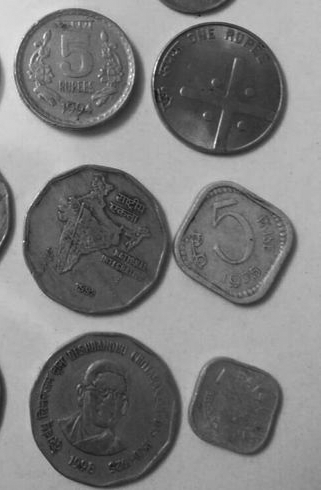

In [2]:
coins = cv2.imread('Monety_szare.bmp', cv2.IMREAD_GRAYSCALE)
Image.fromarray(coins)

Rozwiązanie:

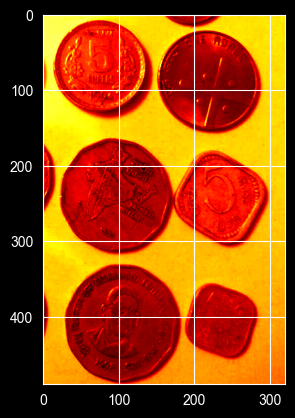

In [3]:
plt.imshow(coins, cmap='hot')

Obraz monet w skali szarości został wyświetlony z użyciem mapy ciepła (hot). Najjaśniejsze obszary tła są odwzorowane w odcieniach żółci i bieli, natomiast ciemniejsze monety przyjmują barwy czerwone i czarne.

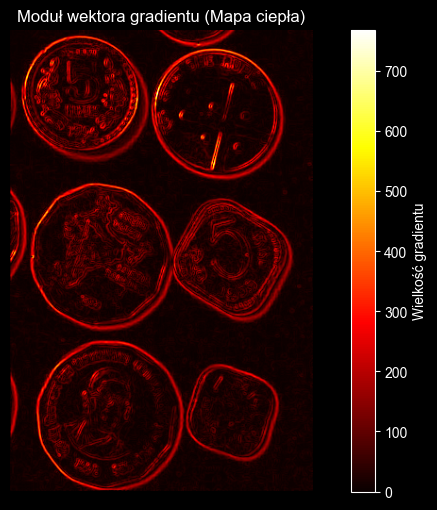

In [4]:
sobelx = cv2.Sobel(coins, cv2.CV_64F, 1, 0, ksize=3)
sobely = cv2.Sobel(coins, cv2.CV_64F, 0, 1, ksize=3)

gradient_magnitude = cv2.magnitude(sobelx, sobely)

plt.figure(figsize=(10, 6))
plt.imshow(gradient_magnitude, cmap='hot')
plt.colorbar(label='Wielkość gradientu')
plt.title('Moduł wektora gradientu (Mapa ciepła)')
plt.axis('off')
plt.show()

* Czarny i ciemnoczerwony kolor (wartości bliskie 0) odpowiadają obszarom jednorodnym, natomiast odcienie jasnoczerwone, pomarańczowe i żółte wskazują miejsca o silnych zmianach jasności (krawędzie).
* Pasek skali (colorbar) wskazuje, że wartość modułu gradientu sięga ponad 700 jednostek na najbardziej wyrazistych krawędziach.


1. **Gdzie gradienty są bliskie zera?**
* Gradienty dążą do zera (obszary czarne na obrazie) w **jednolitym tłu** wokół monet oraz w **płaskich, wygładzonych fragmentach powierzchni monet**, gdzie jasność pikseli nie ulega gwałtownym zmianom.

2. **Czy uzyskany wynik pozwoliłby np. na detekcję poszczególnych obiektów?**
* **Nie bezpośrednio**, chociaż stanowi doskonały punkt wyjścia.
* Moduł gradientu uwypukla krawędzie zewnętrzne monet, ale reaguje również na **wewnętrzne reliefy, cyfry i wzory** znajdujące się na ich powierzchni.


Aby wyodrębnić i zliczyć konkretne obiekty, sam obraz gradientowy wymaga dalszego przetwarzania, np.:
1. **Progowania (binaryzacji)** - w celu odrzucenia słabszych odpowiedzi i uzyskania masek krawędzi.

2. **Operacji morfologicznych** - do domknięcia konturów i wypełnienia wnętrza monet.
3. **Algorytmów detekcji obiektów** - takich jak `cv2.findContours()` lub **Transformacja Hougha dla okręgów** (`cv2.HoughCircles()`).

---

##### Zad. 2: Detekcja krawędzi

Przeprowadź z obrazem `coins_noise` takie przekształcenia, aby zmaksymalizować możliwość rozpoznania obiektów. Wykorzystaj [filtr Canny'ego](https://docs.opencv.org/4.x/dd/d1a/group__imgproc__feature.html#ga04723e007ed888ddf11d9ba04e2232de) do detekcji krawędzi; zbadaj jego zachowanie w zależności od wartości **progów** oraz sposobu redukcji **szumu**.

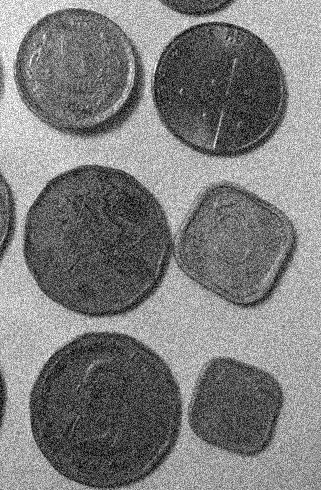

In [5]:
coins_noise = cv2.imread('Monety_szare_szum.bmp', cv2.IMREAD_GRAYSCALE)
Image.fromarray(coins_noise)

Rozwiązanie:

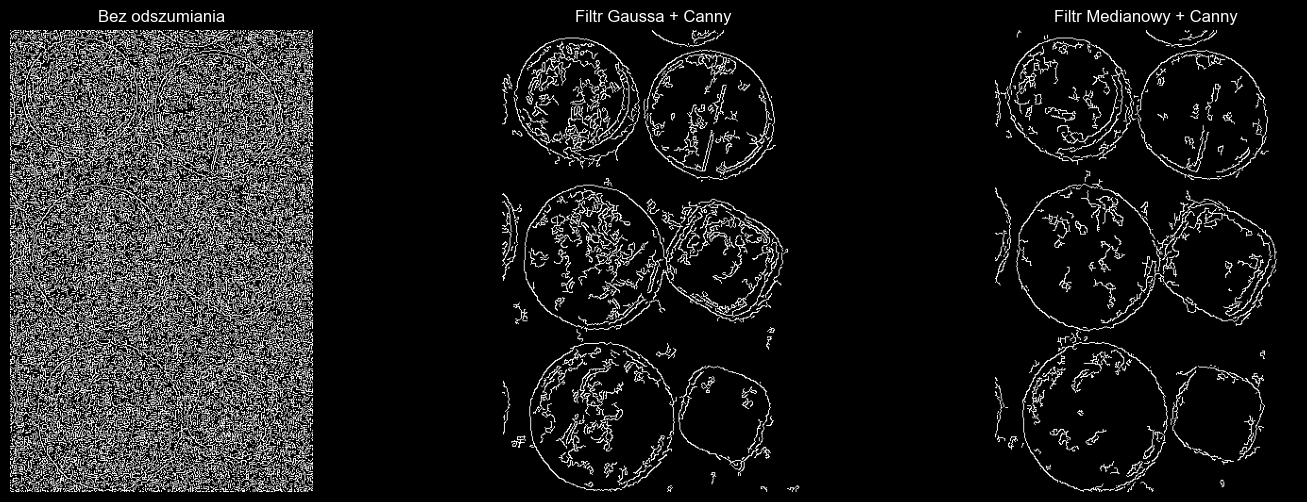

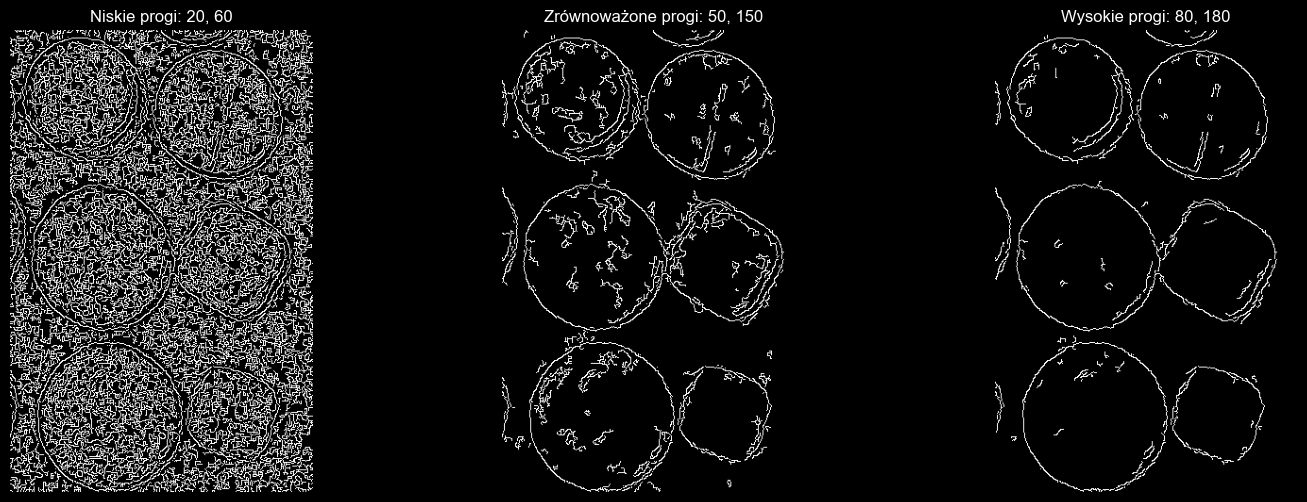

In [12]:
blur_gauss = cv2.GaussianBlur(coins_noise, (5, 5), 0)
blur_median = cv2.medianBlur(coins_noise, 5)

canny_raw = cv2.Canny(coins_noise, 50, 150)
canny_gauss = cv2.Canny(blur_gauss, 50, 150)
canny_median = cv2.Canny(blur_median, 50, 150)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
axes[0].imshow(canny_raw, cmap='gray')
axes[0].set_title('Bez odszumiania')
axes[0].axis('off')

axes[1].imshow(canny_gauss, cmap='gray')
axes[1].set_title('Filtr Gaussa + Canny')
axes[1].axis('off')

axes[2].imshow(canny_median, cmap='gray')
axes[2].set_title('Filtr Medianowy + Canny')
axes[2].axis('off')
plt.show()


canny_low = cv2.Canny(blur_median, 20, 60)
canny_mid = cv2.Canny(blur_median, 50, 150)
canny_high = cv2.Canny(blur_median, 80, 180)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
axes[0].imshow(canny_low, cmap='gray')
axes[0].set_title('Niskie progi: 20, 60')
axes[0].axis('off')

axes[1].imshow(canny_mid, cmap='gray')
axes[1].set_title('Zrównoważone progi: 50, 150')
axes[1].axis('off')

axes[2].imshow(canny_high, cmap='gray')
axes[2].set_title('Wysokie progi: 80, 180')
axes[2].axis('off')
plt.show()

#### Wpływ redukcji szumu
* Obraz wejściowy bez wstępnej filtracji generuje siatkę fałszywych krawędzi na całym tłu, całkowicie uniemożliwiając rozpoznanie obiektów.

* Filtracja Gaussowska liniowo rozmywa obraz, co przy szumie impulsowym nie usuwa zakłóceń całkowicie i pozostawia drobne artefakty.


* Filtracja medianowa eliminuje szum impulsowy bez rozmywania krawędzi, dzięki czemu zapewnia najczystsze tło pod dalszą analizę.

#### Wpływ progów histerezy (dolny rząd)
* **Progi histerezy (20, 60):** Detektor jest nadmiernie czuły — przepuszcza drobne zakłócenia tła oraz wyłapuje pełną strukturę powierzchniową (reliefy i fakturę) wnętrza monet.


* **Progi histerezy (50, 150):** Zachodzi znaczna redukcja szumu tła, jednak we wnętrzu obiektów wciąż pozostają widoczne niepożądane krawędzie tekstury monet.


* **Progi histerezy (80, 180) – zestaw optymalny:** Podwyższenie progów skutecznie wycina resztki niepotrzebnych detali z wnętrza monet, nie powodując przy tym pękania ani utraty ciągłości ich zewnętrznych obrysów.


* **Wniosek:** Połączenie filtracji medianowej z progami **(80, 180)** daje najbardziej precyzyjne, zamknięte kontury obiektów, stanowiące idealny materiał wejściowy do dalszej segmentacji oraz zliczania (np. za pomocą `cv2.findContours()` lub `cv2.HoughCircles()`).

---

##### Zad. 3: Wyrównanie histogramu

Wyrównaj histogram obrazu `coins_noise`. Wyniki zaprezentuj za pomocą obrazów i towarzyszących im histogramów. Powtórz eksperyment z detekcją krawędzi (zad. 2) dla wyrównanego obrazu i omów różnice.

C:\Users\pauko\AppData\Local\Temp\ipykernel_5768\2252992401.py:9: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.10; the parameter will become keyword-only in 3.12.
  axes[0, 1].hist(coins_noise.ravel(), 256, [0, 256], color='gray')
C:\Users\pauko\AppData\Local\Temp\ipykernel_5768\2252992401.py:16: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.10; the parameter will become keyword-only in 3.12.
  axes[1, 1].hist(coins_eq.ravel(), 256, [0, 256], color='gray')


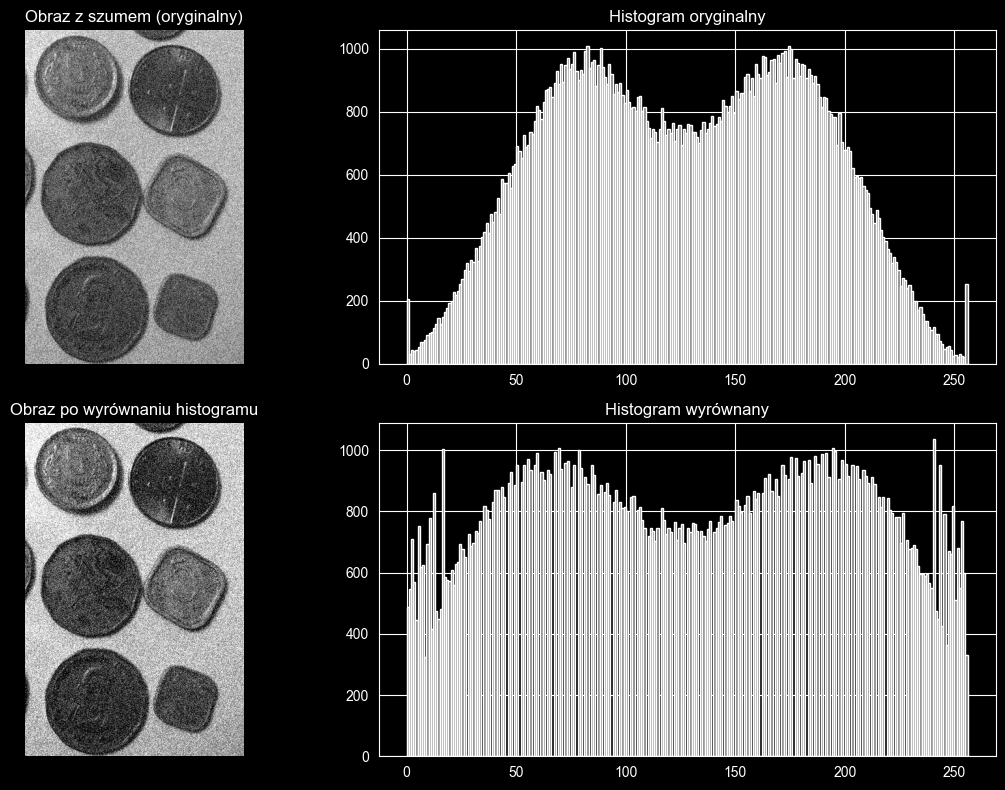

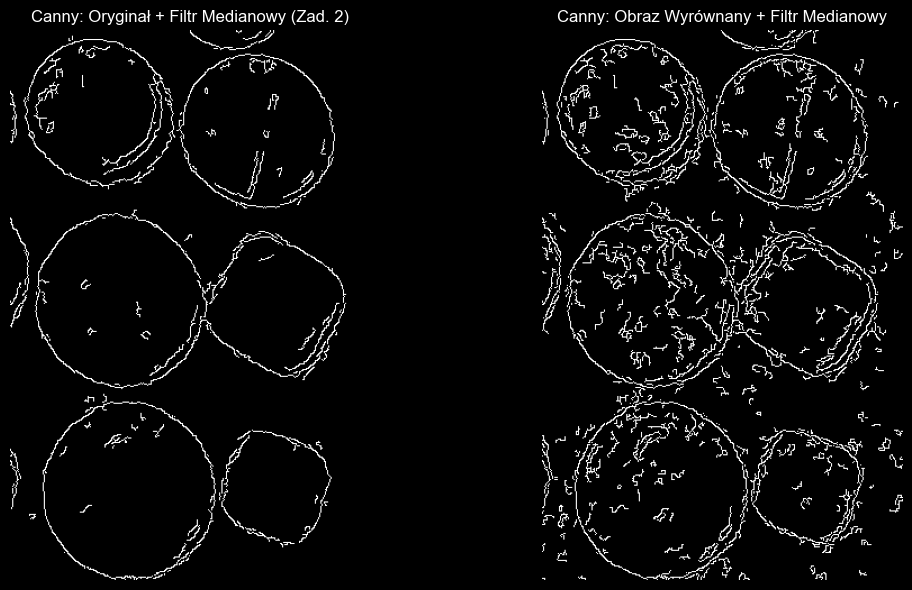

In [13]:
coins_eq = cv2.equalizeHist(coins_noise)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

axes[0, 0].imshow(coins_noise, cmap='gray')
axes[0, 0].set_title('Obraz z szumem (oryginalny)')
axes[0, 0].axis('off')

axes[0, 1].hist(coins_noise.ravel(), 256, [0, 256], color='gray')
axes[0, 1].set_title('Histogram oryginalny')

axes[1, 0].imshow(coins_eq, cmap='gray')
axes[1, 0].set_title('Obraz po wyrównaniu histogramu')
axes[1, 0].axis('off')

axes[1, 1].hist(coins_eq.ravel(), 256, [0, 256], color='gray')
axes[1, 1].set_title('Histogram wyrównany')

plt.tight_layout()
plt.show()

blur_eq_median = cv2.medianBlur(coins_eq, 5)

canny_orig_median = cv2.Canny(cv2.medianBlur(coins_noise, 5), 80, 180)
canny_eq_median = cv2.Canny(blur_eq_median, 80, 180)

fig, axes = plt.subplots(1, 2, figsize=(12, 6))

axes[0].imshow(canny_orig_median, cmap='gray')
axes[0].set_title('Canny: Oryginał + Filtr Medianowy (Zad. 2)')
axes[0].axis('off')

axes[1].imshow(canny_eq_median, cmap='gray')
axes[1].set_title('Canny: Obraz Wyrównany + Filtr Medianowy')
axes[1].axis('off')

plt.tight_layout()
plt.show()

#### Omówienie wyników

* **Oryginał i jego histogram -** Oryginalny obraz zawiera szum impulsowy, a jego histogram jest skupiony w ograniczonej części zakresu tonalnego.


* **Obraz wyrównany i jego histogram -** Wyrównanie histogramu rozciągnęło jasność na całą skalę $[0, 255]$. Efektem ubocznym jest drastyczne podbicie kontrastu szumu w tle oraz uwypuklenie drobnych rys i tłoczeń na monetach.


* **Detekcja Canny na oryginale (lewy dół) -** Połączenie filtra medianowego i algorytmu Canny pozwala uzyskać gładkie tło oraz czyste, spójne obrysy monet.


* **Detekcja Canny na obrazie wyrównanym (prawy dół) -** Detektor Canny generuje gęstą siatkę fałszywych krawędzi zarówno na tłu, jak i wewnątrz obiektów.

#### Główne różnice

1. Wyrównanie histogramu drastycznie zwiększa różnice tonalne pomiędzy pikselami szumu a tłem. Przez to filtr medianowy nie jest w stanie całkowicie wygładzić zakłóceń przed detekcją krawędzi.


2. Wzmocniony szum tworzy sztuczne, silne gradienty, które przekraczają progi histerezy i są błędnie kwalifikowane jako krawędzie obiektów.


3. Obraz wynikowy dla oryginału nadaje się do natychmiastowej segmentacji i zliczania monet, natomiast wynik dla obrazu wyrównanego jest nieczytelny i zaszumiony.


Nie należy wykonywać globalnego wyrównywania histogramu przed detekcją krawędzi na obrazach zaszumionych. Operacja ta zwiększa poziom zakłóceń i uniemożliwia poprawną detekcję obrysów obiektów.

---

##### Zad. 4: Transformacja do rozkładu docelowego

Dla obrazów `albatross_single` (od tego zacznij) i `albatross_crowd` wykonaj transformację do wybranego (założonego przez siebie) rozkładu docelowego, tak aby zmaksymalizować możliwość wyodrębnienia obiektów (albatrosów) z otoczenia przy użyciu algorytmu binaryzacji Otsu. Zbadaj wpływ kształtu rozkładu docelowego na zachowanie transformacji.  
Jaki(e) parametr(y) rozkładu są najistotniejsze?

Podpowiedź: przedstawiona we wstępie teoretycznym transformacja obu rozkładów (źródłowego i docelowego) do rozkładu jednostajnego nie musi zostać wykonana _wprost_ (dlatego nie używaj w zadaniu funkcji `cv2.equalizeHist`)! Wystarczy porównywanie ze sobą wartości ze skumulowanych rozkładów (rysunek 3).

Podpowiedź 2: [`cv2.LUT`](https://docs.opencv.org/4.5.3/d2/de8/group__core__array.html#gab55b8d062b7f5587720ede032d34156f)

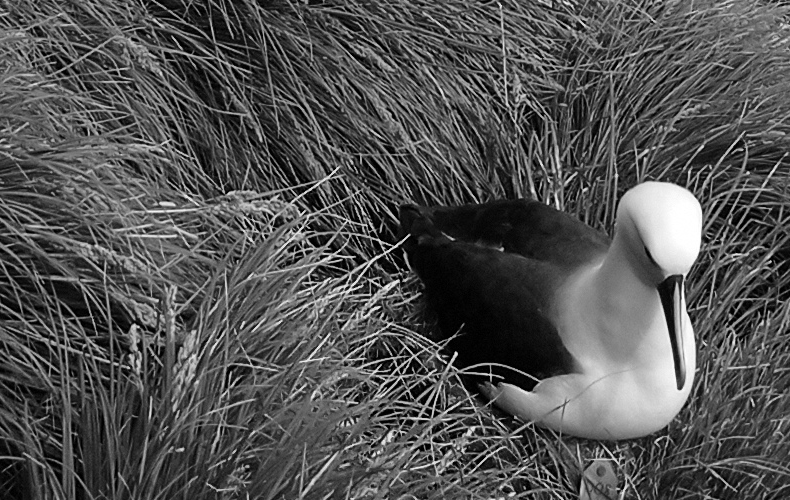

In [8]:
albatross_single = cv2.imread('albatross_single.png', cv2.IMREAD_GRAYSCALE)
Image.fromarray(albatross_single)

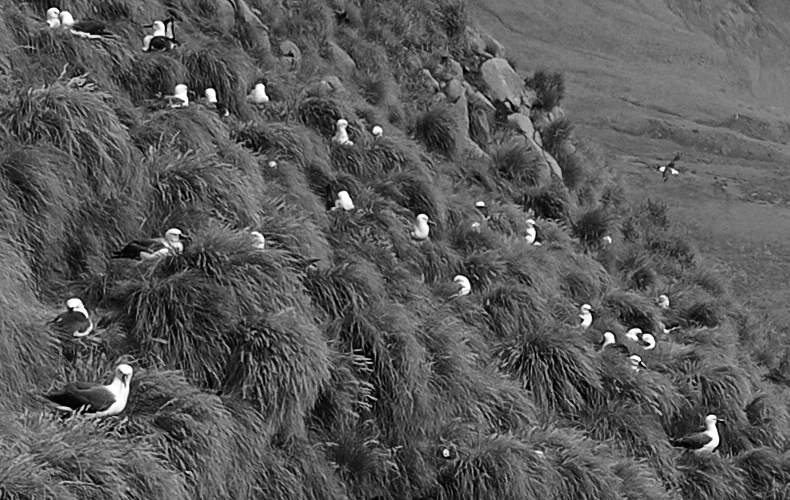

In [9]:
albatross_crowd = cv2.imread('albatross_crowd.png', cv2.IMREAD_GRAYSCALE)
Image.fromarray(albatross_crowd)

Rozwiązanie:

C:\Users\pauko\AppData\Local\Temp\ipykernel_5768\604108428.py:42: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.10; the parameter will become keyword-only in 3.12.
  ax[1].hist(matched.ravel(), 256, [0, 256], color='blue', alpha=0.6)


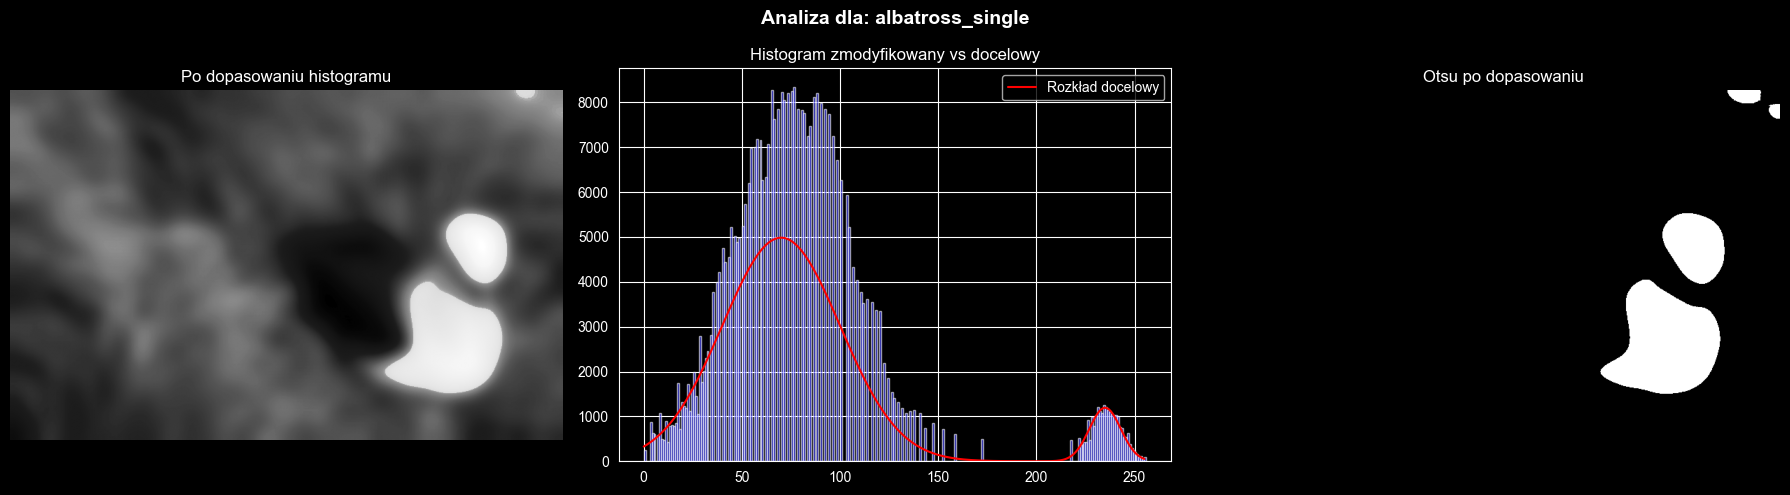

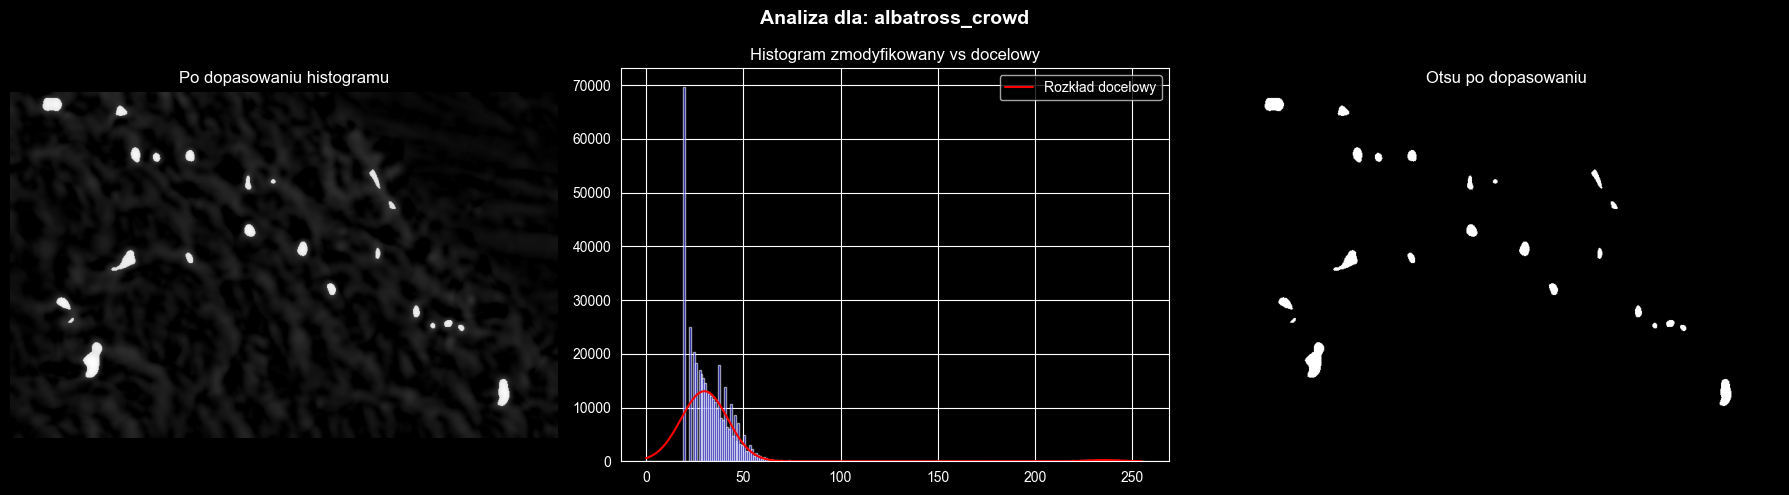

In [26]:
def histogram_matching(img, target_pdf):
    hist_src, _ = np.histogram(img.ravel(), 256, [0, 256])
    cdf_src = (hist_src / hist_src.sum()).cumsum()
    cdf_target = (target_pdf / target_pdf.sum()).cumsum()
    lut = np.searchsorted(cdf_target, cdf_src).clip(0, 255).astype(np.uint8)
    return cv2.LUT(img, lut)

def make_pdf(mu1, s1, mu2, s2, w_bright):
    x = np.arange(256)
    return ((1 - w_bright) * np.exp(-0.5 * ((x - mu1) / s1) ** 2) / s1 +
            w_bright * np.exp(-0.5 * ((x - mu2) / s2) ** 2) / s2)

images = {'albatross_single': albatross_single, 'albatross_crowd': albatross_crowd}

CONFIG = {
    'albatross_single': dict(blur=14,  tophat=None, w_bright=0.06,
                             mu1=70, s1=30, mu2=235, s2=8),
    'albatross_crowd':  dict(blur=4.5, tophat=41,   w_bright=0.012,
                             mu1=30, s1=12, mu2=235, s2=8),
}

for name, img in images.items():
    c = CONFIG[name]

    work = cv2.GaussianBlur(img, (0, 0), c['blur'])
    if c['tophat']:
        k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (c['tophat'], c['tophat']))
        work = cv2.morphologyEx(work, cv2.MORPH_TOPHAT, k)

    pdf = make_pdf(c['mu1'], c['s1'], c['mu2'], c['s2'], c['w_bright'])
    matched = histogram_matching(work, pdf)
    _, otsu_matched = cv2.threshold(matched, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

    fig, ax = plt.subplots(1, 3, figsize=(18, 5))
    fig.suptitle(f'Analiza dla: {name}', fontsize=14, fontweight='bold')

    ax[0].imshow(matched, cmap='gray')
    ax[0].set_title('Po dopasowaniu histogramu')
    ax[0].axis('off')

    ax[1].hist(matched.ravel(), 256, [0, 256], color='blue', alpha=0.6)
    ax[1].plot(np.arange(256), pdf * work.size / pdf.sum(), 'r', label='Rozkład docelowy')
    ax[1].set_title('Histogram zmodyfikowany vs docelowy')
    ax[1].legend()

    ax[2].imshow(otsu_matched, cmap='gray')
    ax[2].set_title('Otsu po dopasowaniu')
    ax[2].axis('off')

    plt.tight_layout()
    plt.show()

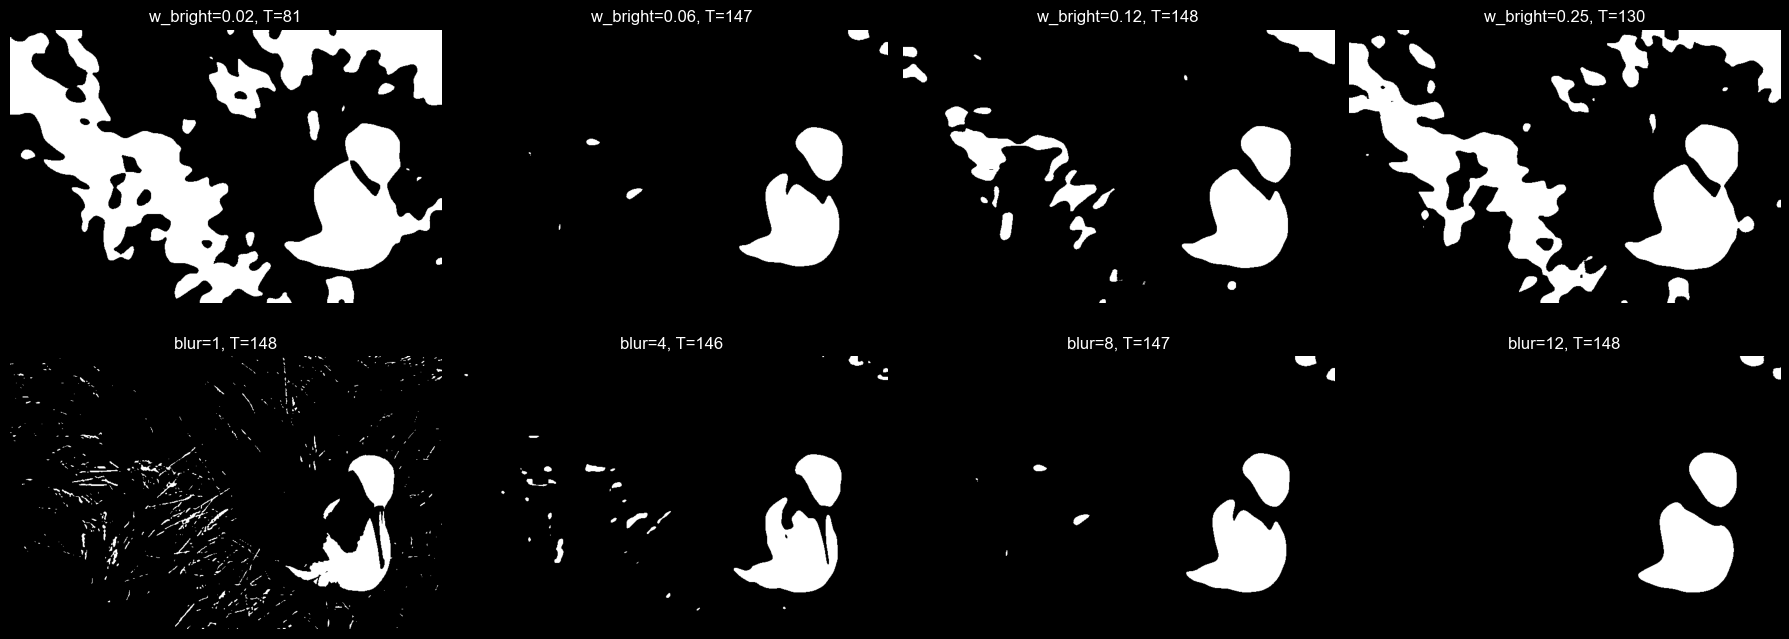

In [23]:
def run_otsu(img, blur, tophat, **pdf_params):
    work = cv2.GaussianBlur(img, (0, 0), blur)
    if tophat:
        k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (tophat, tophat))
        work = cv2.morphologyEx(work, cv2.MORPH_TOPHAT, k)
    matched = histogram_matching(work, make_pdf(**pdf_params))
    t, mask = cv2.threshold(matched, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    return mask, t

c = CONFIG['albatross_single']
fig, ax = plt.subplots(2, 4, figsize=(18, 7))
for a, w in zip(ax[0], [0.02, 0.06, 0.12, 0.25]):
    m, t = run_otsu(albatross_single, c['blur'], None,
                    mu1=c['mu1'], s1=c['s1'], mu2=c['mu2'], s2=c['s2'], w_bright=w)
    a.imshow(m, cmap='gray'); a.set_title(f'w_bright={w}, T={t:.0f}'); a.axis('off')
for a, b in zip(ax[1], [1, 4, 8, 12]):
    m, t = run_otsu(albatross_single, b, None,
                    mu1=c['mu1'], s1=c['s1'], mu2=c['mu2'], s2=c['s2'], w_bright=c['w_bright'])
    a.imshow(m, cmap='gray'); a.set_title(f'blur={b}, T={t:.0f}'); a.axis('off')
plt.tight_layout(); plt.show()

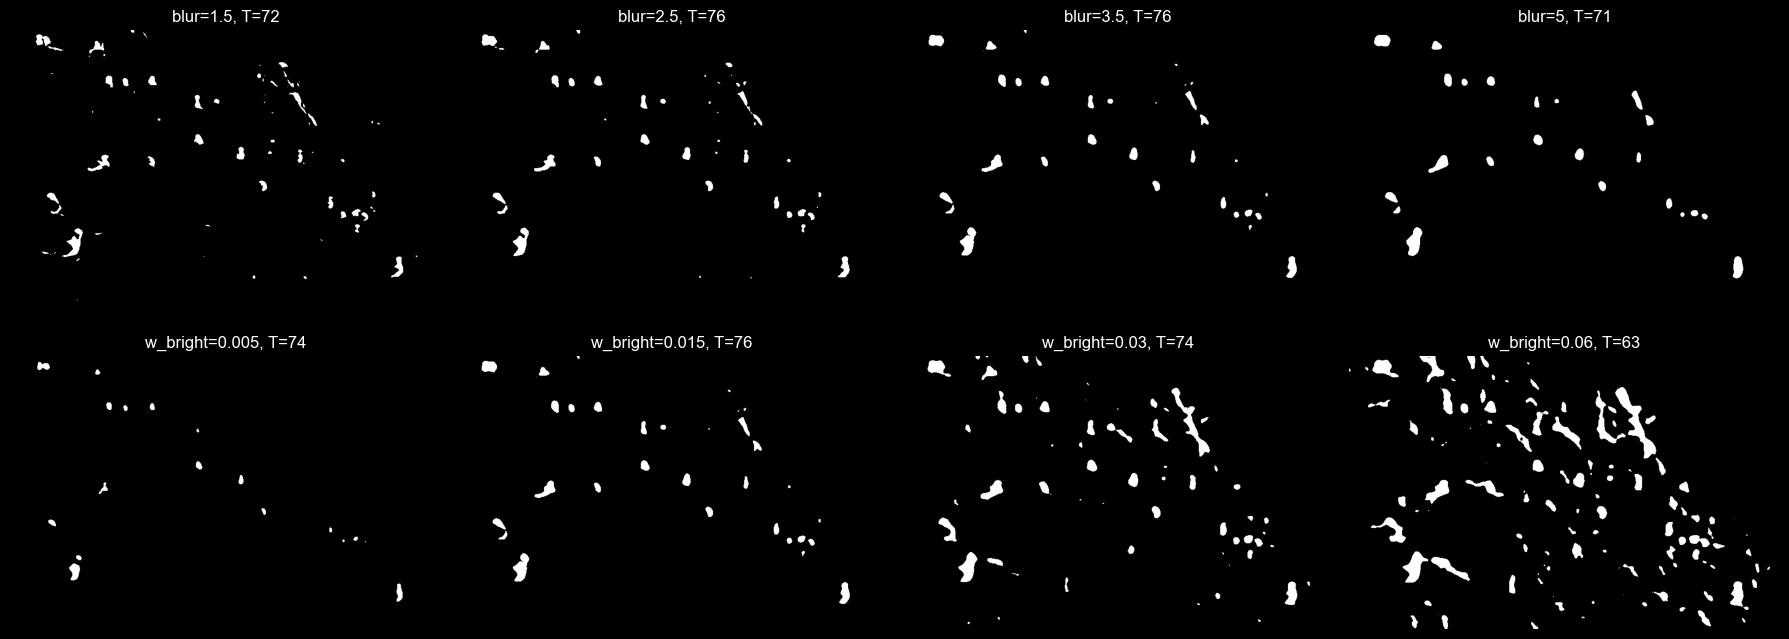

In [25]:
c = CONFIG['albatross_crowd']
fig, ax = plt.subplots(2, 4, figsize=(18, 7))
for a, b in zip(ax[0], [1.5, 2.5, 3.5, 5]):
    m, t = run_otsu(albatross_crowd, b, c['tophat'],
                    mu1=c['mu1'], s1=c['s1'], mu2=c['mu2'], s2=c['s2'], w_bright=c['w_bright'])
    a.imshow(m, cmap='gray'); a.set_title(f'blur={b}, T={t:.0f}'); a.axis('off')
for a, w in zip(ax[1], [0.005, 0.015, 0.03, 0.06]):
    m, t = run_otsu(albatross_crowd, c['blur'], c['tophat'],
                    mu1=c['mu1'], s1=c['s1'], mu2=c['mu2'], s2=c['s2'], w_bright=w)
    a.imshow(m, cmap='gray'); a.set_title(f'w_bright={w}, T={t:.0f}'); a.axis('off')
plt.tight_layout(); plt.show()

#### 1. `albatross_single`

* **Rozkład docelowy:** mieszanina dwóch gaussów (ciemne tło: μ=70, σ=30; jasny obiekt: μ=235, σ=8, waga 0,06).
* **Po transformacji:** histogram jest wyraźnie bimodalny, z przerwą między ok. 150 a 215. Otsu ustawia próg w T≈147, czyli tuż za ciemnym pasmem.
* **Efekt Otsu:** maska zawiera sylwetkę ptaka (korpus i głowa). Zostają pojedyncze plamki i obiekt przy krawędzi kadru. To jasne struktury o jasności zbliżonej do ptaka, których transformacja nie odróżni.

#### 2. `albatross_crowd`

* **Przetwarzanie wstępne:** top-hat (41) usuwa tło o wolnej zmienności, a rozmycie (σ=4,5) usuwa cienkie źdźbła.
* **Po transformacji:** histogram wygląda na jednomodalny. W rzeczywistości rozkład docelowy jest dwumodalny, ale drugi pik jest niewidoczny na wykresie z trzech powodów:
  * **Mała waga jasnego piku** (`w_bright`=0,012). Ptaki zajmują ok. 1 % pikseli, więc jasny pik zawiera ich zaledwie kilka tysięcy, rozłożonych na ok. 40 wartościach jasności (215-255). To kilkadziesiąt pikseli na wartość.
  * **Skala wykresu.** Ciemny pik ma wysokość ok. 13 000, a słupek przy ok. 17 sięga 70 000. Słupki o wysokości kilkudziesięciu pikseli są na tej skali nieodróżnialne od zera, podobnie jak czerwona krzywa jasnego piku.
  * **Wąski ciemny pik** (`s1`=12) po top-hat. Prawie wszystkie piksele mają wartość bliską 0, więc skupiają się w jednym wąskim paśmie, które dominuje wykres.
* **Dyskretność:** słupek przy ok. 17 to piksele o wartości 0 po top-hat. Dopasowanie histogramu przypisuje je wszystkie do jednej wartości wyjściowej, więc nie można ich rozłożyć na szerszy zakres.
* **Efekt Otsu:** brak widocznego drugiego piku nie przeszkadza. Otsu minimalizuje wariancję wewnątrzklasową i potrzebuje tylko tego, żeby jasne piksele leżały daleko od ciemnych (ok. 235 vs ok. 30). Próg T≈74-76 jest stabilny, a w masce zostają zwarte plamy odpowiadające ptakom.
* **Wniosek:** histogram wygląda na jednomodalny, bo obiekty zajmują bardzo mały ułamek obrazu. Rozkład jest dwumodalny, tylko jeden z modów jest za mały, żeby go zobaczyć.

#### Wpływ parametrów

* **`w_bright` jest najistotniejszy.** Na `single` w zakresie 0,06-0,12 próg stoi w T≈147, a przy 0,02 spada do 81 i maska zalewa trawę. Przy 0,25 próg spada do 130 i trawa też trafia do maski. Na `crowd` przy 0,06 próg spada do 63 i maska zalewa się szumem. Waga powinna odpowiadać rzeczywistemu udziałowi obiektów w obrazie.
* **Rozmycie (`blur`) decyduje o ilości śmieci w masce, ale nie o progu.** T jest prawie stałe (≈146-148), a rośnie czystość maski, bo małe struktury (źdźbła, odblaski) znikają, a duże obiekty zostają. Zbyt duże rozmycie zaokrągla kontury.
* **Odległość `mu2 − mu1` względem `s1` i `s2`** wpływa na stabilność progu: im wyraźniejsza przerwa między modami, tym mniej wynik zależy od drobnych zmian. `s1`, `mu1` i `s2` mają mniejsze znaczenie.
* **Ogólny wniosek:** transformacja zmienia wartości jasności, ale nie zmienia uporządkowania pikseli, więc sama nie odróżni ptaka od odblasku o tej samej jasności. Rozdzielenie obiektów różnej wielkości zapewnia dopiero wstępne filtrowanie.

#### Ograniczenia: brakujące ogony i końcówki skrzydeł

* Na masce `single` nie widać ogona ani ciemnych końcówek skrzydeł. Mają one jasność zbliżoną do trawy i cienia, więc Otsu, który dzieli piksele wyłącznie po jasności, przypisuje je do tła.
* Obniżenie progu, żeby je odzyskać, wpuściłoby do maski trawę, czyli dokładnie to, co udało się usunąć. Żaden rozkład docelowy tego nie naprawi.
* Dla zadania (wyodrębnienie obiektów) to ograniczenie jest akceptowalne, bo ciało i głowa dają poprawną lokalizację i przybliżony kształt. Pełny kontur wymagałby kroku poza transformacją rozkładu (np. domknięcie morfologiczne) albo segmentacji uwzględniającej kształt lub teksturę.